In [ ]:
!pip install -q transformers scikit-learn matplotlib seaborn pandas

import os
import gc
import time
import json
import hashlib
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
    set_seed
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Perangkat aktif : {device}")
if device.type == "cuda":
    print(f"Nama GPU        : {torch.cuda.get_device_name(0)}")
    print(f"VRAM Total      : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
else:
    print("PERINGATAN: GPU belum aktif! Aktifkan GPU T4 sebelum menjalankan eksperimen.")

Perangkat aktif : cuda
Nama GPU        : Tesla T4
VRAM Total      : 14.56 GB


# Soal 1: Rancangan Eksperimen Sistematis

## 1. Pilihan Dataset & Alasan Ukuran Subset
- **Dataset:** SmSA (IndoNLU) — klasifikasi sentimen teks Bahasa Indonesia 3 kelas (`negative`, `neutral`, `positive`).
- **Ukuran Subset:**
  - Data latih: **3.500 sampel** (stratified sampling, berada pada rentang ketentuan 3.000–6.000 sampel agar seluruh run selesai dalam satu sesi GPU T4 dengan menjaga proporsi kelas minoritas `neutral` ~10%).
  - Data validasi: **Seluruh data validasi resmi hasil pembersihan** (>500 sampel), digunakan hanya untuk memilih epoch terbaik.
  - Data uji: **Seluruh data uji resmi (500 kalimat)**, hanya disentuh satu kali per run menggunakan bobot epoch terbaik.

## 2. Matriks Eksperimen (Backbone × Strategi)
| Backbone | Model HuggingFace | Full Fine-Tuning | Partial Freezing | Linear Probing |
| :--- | :--- | :---: | :---: | :---: |
| **BERT** | `bert-base-multilingual-cased` | ✅ (3 seed) | ✅ (3 seed) | ✅ (3 seed) |
| **DistilBERT** | `distilbert-base-multilingual-cased` | ✅ (3 seed) | ✅ (3 seed) | ✅ (3 seed) |
| **IndoBERT** | `indobenchmark/indobert-base-p1` | ✅ (3 seed) | ✅ (3 seed) | ✅ (3 seed) |

*(Catatan: Jika waktu terbatas, gunakan mode `MINIMUM` [Full + Partial = 18 run]; jika waktu cukup, gunakan mode `PENUH` [Full + Partial + Probing = 27 run]).*

## 3. Variabel Terkendali (Dikunci di Seluruh Run)
- `max_length`: **128**
- `batch_size`: **32**
- `epochs`: **3**
- `seeds`: **[42, 123, 2026]** (3 seed identik untuk seluruh kombinasi)
- `learning_rate`: **2e-5** (Full & Partial Fine-Tuning), **2e-3** (Linear Probing)
- `optimizer`: AdamW (`weight_decay=0.01`) + Linear Warmup (10% langkah)

## 4. Hipotesis Eksperimen (H1–H3)
- **H1 (Backbone):** IndoBERT (`indobenchmark/indobert-base-p1`) akan menghasilkan F1 makro tertinggi karena dilatih khusus pada korpus Bahasa Indonesia, sedangkan DistilBERT akan memberikan waktu latih dan inferensi tercepat dengan penurunan F1 makro yang moderat.
- **H2 (Strategi Fine-Tuning):** Full Fine-Tuning akan memperoleh F1 makro tertinggi, Partial Freezing akan menghasilkan skor yang sangat kompetitif (selisih mendekati atau di bawah simpangan baku antar-seed) dengan waktu latih lebih singkat, sedangkan Linear Probing akan memiliki skor terendah meski paling hemat komputasi.
- **H3 (Trade-off):** Kombinasi IndoBERT dengan Partial Freezing (atau Full Fine-Tuning jika anggaran komputasi memadai) akan memberikan keseimbangan terbaik antara F1 makro, kecepatan inferensi, dan biaya pelatihan.

In [ ]:
# ==============================================================================
# KONFIGURASI EKSPERIMEN & GUARD SEL RANCANGAN
# ==============================================================================
# Pilihan MODE:
# - "UJI_CEPAT" : 1 backbone x 2 strategi x 1 seed (untuk tes kode ~2 menit)
# - "MINIMUM"   : 3 backbone x 2 strategi (full, partial) x 3 seed = 18 run (~35-55 menit di T4)
# - "PENUH"     : 3 backbone x 3 strategi (full, partial, probing) x 3 seed = 27 run (~50-75 menit di T4)
MODE = "PENUH"  # <-- Ganti ke "PENUH" jika ingin menjalankan 27 run (matriks bawaan)

RANCANGAN = {
    "dataset": "smsa",
    "alasan_dataset": "SmSA (IndoNLU) sesuai konteks studi kasus sentimen Bahasa Indonesia 3 kelas dengan uji resmi 500 kalimat.",
    "alasan_subset": "Subset latih 3.500 sampel (rentang 3.000-6.000) secara stratified agar proporsi kelas netral (~10%) terjaga dan seluruh run selesai dalam 1 sesi T4.",
    "hipotesis_H1": "IndoBERT unggul pada F1 makro untuk teks Indonesia; DistilBERT paling cepat pada latih & inferensi.",
    "hipotesis_H2": "Full Fine-Tuning tertinggi, Partial Freezing kompetitif dengan selisih kecil, Linear Probing terendah.",
    "hipotesis_H3": "IndoBERT + Partial Freezing atau DistilBERT + Full Fine-Tuning memberi trade-off akurasi vs efisiensi terbaik."
}

# Validasi wajib: menolak berjalan pada mode penuh/minimum bila rancangan kosong
if MODE in ["MINIMUM", "PENUH"]:
    kosong = [k for k, v in RANCANGAN.items() if not str(v).strip()]
    assert len(kosong) == 0, f"Sel Rancangan belum lengkap! Lengkapi kolom: {kosong}"
    print("✅ Validasi Sel Rancangan lolos.")

# Variabel terkendali (dikunci untuk seluruh run)
DATASET_NAME = "smsa"
N_TRAIN_SUBSET = 3500     # Wajib antara 3.000 - 6.000
MAX_LENGTH = 128
BATCH_SIZE = 32
EPOCHS = 3
USE_AMP = (device.type == "cuda")  # Mixed precision FP16 agar cepat di GPU T4

# Daftar 3 backbone wajib untuk SmSA (TIDAK BOLEH model English-only)
BACKBONES = {
    "BERT": "bert-base-multilingual-cased",
    "DistilBERT": "distilbert-base-multilingual-cased",
    "IndoBERT": "indobenchmark/indobert-base-p1",
    # Opsional nilai plus (hapus tanda # jika ingin ikut dijalankan):
    # "XLM-R": "xlm-roberta-base",
}

# Learning rate per strategi (sesuai spesifikasi: 2e-5-5e-5 full/partial; 1e-3-5e-3 probing)
LR_PER_STRATEGI = {
    "full": 2e-5,
    "partial": 3e-5,
    "probing": 2e-3,
}

if MODE == "UJI_CEPAT":
    BACKBONES_AKTIF = {"DistilBERT": BACKBONES["DistilBERT"]}
    STRATEGI_AKTIF = ["full", "partial"]
    SEEDS = [42]
elif MODE == "MINIMUM":
    BACKBONES_AKTIF = BACKBONES
    STRATEGI_AKTIF = ["full", "partial"]  # Bisa diganti ["full", "probing"]
    SEEDS = [42, 123, 2026]
elif MODE == "PENUH":
    BACKBONES_AKTIF = BACKBONES
    STRATEGI_AKTIF = ["full", "partial", "probing"]
    SEEDS = [42, 123, 2026]
else:
    raise ValueError("MODE harus salah satu dari: UJI_CEPAT, MINIMUM, PENUH")

# Buat kode unik konfigurasi untuk nama berkas CSV otomatis
config_signature = {
    "mode": MODE,
    "dataset": DATASET_NAME,
    "n_train": N_TRAIN_SUBSET,
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "backbones": BACKBONES_AKTIF,
    "strategi": STRATEGI_AKTIF,
    "seeds": SEEDS,
    "lr": {s: LR_PER_STRATEGI[s] for s in STRATEGI_AKTIF},
}
KODE_KONFIG = hashlib.md5(json.dumps(config_signature, sort_keys=True).encode()).hexdigest()[:8]

FILE_HASIL = f"hasil_{DATASET_NAME}_{KODE_KONFIG}.csv"
FILE_REKAP = f"rekap_agregat_{DATASET_NAME}_{KODE_KONFIG}.csv"

total_runs = len(BACKBONES_AKTIF) * len(STRATEGI_AKTIF) * len(SEEDS)
print(f"Mode aktif        : {MODE} ({total_runs} run)")
print(f"Kode konfigurasi  : {KODE_KONFIG}")
print(f"Output CSV run    : {FILE_HASIL}")
print(f"Output CSV rekap  : {FILE_REKAP}")

✅ Validasi Sel Rancangan lolos.
Mode aktif        : PENUH (27 run)
Kode konfigurasi  : 1d2c599b
Output CSV run    : hasil_smsa_1d2c599b.csv
Output CSV rekap  : rekap_agregat_smsa_1d2c599b.csv


In [ ]:
# ==============================================================================
# UNDUH & PEMBERSIHAN DATA SmSA (IndoNLU)
# ==============================================================================
BASE_URL = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa"
URL_TRAIN = f"{BASE_URL}/train_preprocess.tsv"
URL_VALID = f"{BASE_URL}/valid_preprocess.tsv"
URL_TEST  = f"{BASE_URL}/test_preprocess.tsv"

LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

def load_smsa_tsv(url):
    df = pd.read_csv(url, sep="\t", header=None, names=["text", "label_str"])
    df = df.dropna(subset=["text", "label_str"]).copy()
    df["text"] = df["text"].astype(str).str.strip()
    df["label_str"] = df["label_str"].astype(str).str.strip().str.lower()
    df = df[df["label_str"].isin(LABEL2ID.keys())].copy()
    df["label"] = df["label_str"].map(LABEL2ID)
    return df.reset_index(drop=True)

df_train_raw = load_smsa_tsv(URL_TRAIN)
df_valid_raw = load_smsa_tsv(URL_VALID)
df_test_raw  = load_smsa_tsv(URL_TEST)

print(f"Ukuran awal -> Train: {len(df_train_raw)}, Valid: {len(df_valid_raw)}, Test: {len(df_test_raw)}")

def bersihkan_split(df, nama_split):
    awal = len(df)
    # 1. Buang teks yang memiliki label bertentangan
    konflik = df.groupby("text")["label"].nunique()
    teks_konflik = set(konflik[konflik > 1].index)
    df_clean = df[~df["text"].isin(teks_konflik)].copy()
    n_konflik = awal - len(df_clean)

    # 2. Buang duplikat teks
    sebelum_dup = len(df_clean)
    df_clean = df_clean.drop_duplicates(subset=["text"]).reset_index(drop=True)
    n_dup = sebelum_dup - len(df_clean)

    print(f"[{nama_split}] Buang konflik label: {n_konflik} | Buang duplikat: {n_dup} | Sisa: {len(df_clean)}")
    return df_clean

df_train_clean = bersihkan_split(df_train_raw, "Train")
df_valid_clean = bersihkan_split(df_valid_raw, "Valid")

# 3. Buang teks validasi yang juga ada di data latih (mencegah kebocoran validasi)
train_text_set = set(df_train_clean["text"])
sebelum_bocoran = len(df_valid_clean)
df_valid_clean = df_valid_clean[~df_valid_clean["text"].isin(train_text_set)].reset_index(drop=True)
print(f"[Valid] Buang teks tumpang tindih dengan Train: {sebelum_bocoran - len(df_valid_clean)} | Sisa Valid: {len(df_valid_clean)}")

# 4. Data uji resmi dipertahankan utuh (500 kalimat)
df_test = df_test_raw.copy()

# 5. Stratified subset untuk data latih (3.000 - 6.000 sampel)
assert 3000 <= N_TRAIN_SUBSET <= 6000, "Ukuran subset latih harus antara 3.000 dan 6.000!"
df_train, _ = train_test_split(
    df_train_clean,
    train_size=N_TRAIN_SUBSET,
    stratify=df_train_clean["label"],
    random_state=42
)
df_train = df_train.reset_index(drop=True)
df_valid = df_valid_clean.copy()

assert len(df_valid) >= 500, "Data validasi minimal 500 sampel!"
assert len(df_test) == 500, f"Data uji SmSA resmi seharusnya 500 kalimat, ditemukan {len(df_test)}."

print("\n=== Distribusi Kelas Final ===")
for nama, d in [("Train (Subset)", df_train), ("Valid (Clean)", df_valid), ("Test (Resmi)", df_test)]:
    dist = d["label_str"].value_counts(normalize=True).mul(100).round(1).to_dict()
    print(f"{nama:15s}: n={len(d):4d} | Proporsi (%): {dist}")

Ukuran awal -> Train: 11000, Valid: 1260, Test: 500
[Train] Buang konflik label: 0 | Buang duplikat: 67 | Sisa: 10933
[Valid] Buang konflik label: 0 | Buang duplikat: 0 | Sisa: 1260
[Valid] Buang teks tumpang tindih dengan Train: 14 | Sisa Valid: 1246

=== Distribusi Kelas Final ===
Train (Subset) : n=3500 | Proporsi (%): {'positive': 58.4, 'negative': 31.2, 'neutral': 10.4}
Valid (Clean)  : n=1246 | Proporsi (%): {'positive': 58.4, 'negative': 31.2, 'neutral': 10.4}
Test (Resmi)   : n= 500 | Proporsi (%): {'positive': 41.6, 'negative': 40.8, 'neutral': 17.6}


In [ ]:
# ==============================================================================
# BASELINE PEMBANDING: TF-IDF + LOGISTIC REGRESSION
# ==============================================================================
t0 = time.perf_counter()
tfidf = TfidfVectorizer(max_features=15000, ngram_range=(1, 2))
X_tr_tfidf = tfidf.fit_transform(df_train["text"])
X_te_tfidf = tfidf.transform(df_test["text"])

clf_tfidf = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
clf_tfidf.fit(X_tr_tfidf, df_train["label"])
train_time_tfidf = time.perf_counter() - t0

t_inf0 = time.perf_counter()
pred_tfidf = clf_tfidf.predict(X_te_tfidf)
inf_ms_tfidf = (time.perf_counter() - t_inf0) * 1000 / len(df_test)

acc_tfidf = accuracy_score(df_test["label"], pred_tfidf)
f1_tfidf = f1_score(df_test["label"], pred_tfidf, average="macro")

print("=== Baseline TF-IDF (pada subset latih yang sama) ===")
print(f"Akurasi Uji       : {acc_tfidf:.4f}")
print(f"F1 Makro Uji      : {f1_tfidf:.4f}")
print(f"Waktu Latih       : {train_time_tfidf:.2f} detik")
print(f"Waktu Inferensi   : {inf_ms_tfidf:.4f} ms/kalimat")
print(f"Tebakan Acak (3k) : ~0.3333")

=== Baseline TF-IDF (pada subset latih yang sama) ===
Akurasi Uji       : 0.6360
F1 Makro Uji      : 0.5759
Waktu Latih       : 2.09 detik
Waktu Inferensi   : 0.0021 ms/kalimat
Tebakan Acak (3k) : ~0.3333


In [ ]:
# ==============================================================================
# DATASET PYTORCH & STRATEGI FINE-TUNING (HEAD REPLACEMENT + FREEZING EKSPLISIT)
# ==============================================================================
class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.encodings = tokenizer(
            list(texts),
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt"
        )
        self.labels = torch.tensor(list(labels), dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "labels": self.labels[idx],
        }


def muat_model_dan_strategi(model_name, strategi, num_labels=3):
    """
    1. Head Replacement (wajib semua run): mengganti classification head sesuai jumlah label.
    2. Strategi Fine-Tuning:
       - 'full'    : seluruh parameter dilatih.
       - 'partial' : membekukan embedding + separuh lapis encoder awal
                     (12 lapis -> bekukan 0..5; DistilBERT 6 lapis -> bekukan 0..2).
       - 'probing' : membekukan seluruh backbone, hanya melatih classification head.
    """
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=num_labels,
        ignore_mismatched_sizes=True
    )

    if strategi == "full":
        # Semua parameter aktif dilatih
        for param in model.parameters():
            param.requires_grad = True

    elif strategi == "probing":
        # Bekukan seluruh parameter terlebih dahulu
        for param in model.parameters():
            param.requires_grad = False
        # Aktifkan hanya lapisan kepala klasifikasi (classification head)
        for name, param in model.named_parameters():
            if any(k in name for k in ["classifier", "pre_classifier"]):
                param.requires_grad = True

    elif strategi == "partial":
        # Mulai dari seluruh parameter aktif
        for param in model.parameters():
            param.requires_grad = True

        base = model.base_model

        # 1) Bekukan lapisan embedding
        if hasattr(base, "embeddings"):
            for param in base.embeddings.parameters():
                param.requires_grad = False

        # 2) Identifikasi daftar lapis Transformer (BERT/IndoBERT/RoBERTa vs DistilBERT)
        if hasattr(base, "encoder") and hasattr(base.encoder, "layer"):
            layers = base.encoder.layer
        elif hasattr(base, "transformer") and hasattr(base.transformer, "layer"):
            layers = base.transformer.layer
        else:
            raise ValueError(f"Struktur lapisan encoder tidak dikenali untuk {model_name}")

        # 3) Bekukan separuh lapis awal (12 -> 6 lapis awal; 6 -> 3 lapis awal)
        n_freeze = len(layers) // 2
        for layer in layers[:n_freeze]:
            for param in layer.parameters():
                param.requires_grad = False
    else:
        raise ValueError(f"Strategi tidak dikenali: {strategi}")

    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return model, total_params, trainable_params


# Verifikasi wajib spesifikasi: urutan parameter terlatih harus probing < partial < full
print("=== Verifikasi Urutan Parameter Terlatih (probing < partial < full) ===")
for nama_bb, model_id in BACKBONES_AKTIF.items():
    hitung = {}
    for s in ["probing", "partial", "full"]:
        m_cek, tot, trn = muat_model_dan_strategi(model_id, s, num_labels=3)
        hitung[s] = trn
        del m_cek
    gc.collect()
    assert hitung["probing"] < hitung["partial"] < hitung["full"], (
        f"Urutan parameter gagal pada {nama_bb}: {hitung}"
    )
    print(
        f"✅ {nama_bb:10s} | Total: {tot:,} | "
        f"Probing: {hitung['probing']:,} < Partial: {hitung['partial']:,} < Full: {hitung['full']:,}"
    )

=== Verifikasi Urutan Parameter Terlatih (probing < partial < full) ===


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (24 outputs left out)

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ IndoBERT   | Total: 124,443,651 | Probing: 2,307 < Partial: 43,120,131 < Full: 124,443,651


In [ ]:
# ==============================================================================
# FUNGSI EVALUASI & SATU RUN EKSPERIMEN
# ==============================================================================
@torch.no_grad()
def evaluasi_model(model, loader, ukur_waktu=False):
    model.eval()
    all_preds, all_labels = [], []

    # Warm-up 1 batch sebelum mengukur waktu inferensi agar akurat di GPU
    if ukur_waktu:
        batch_warmup = next(iter(loader))
        with torch.amp.autocast(device_type="cuda", enabled=USE_AMP):
            _ = model(
                input_ids=batch_warmup["input_ids"].to(device),
                attention_mask=batch_warmup["attention_mask"].to(device)
            )
        if device.type == "cuda":
            torch.cuda.synchronize()
        t_start = time.perf_counter()

    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        with torch.amp.autocast(device_type="cuda", enabled=USE_AMP):
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            preds = torch.argmax(outputs.logits, dim=-1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    inf_ms_per_kalimat = None
    if ukur_waktu:
        if device.type == "cuda":
            torch.cuda.synchronize()
        elapsed_ms = (time.perf_counter() - t_start) * 1000.0
        inf_ms_per_kalimat = elapsed_ms / len(all_labels)

    acc = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average="macro")
    return acc, f1_macro, inf_ms_per_kalimat


def jalankan_satu_run(nama_bb, model_id, strategi, seed, train_loader, valid_loader, test_loader):
    # Reproduksibilitas wajib
    set_seed(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    lr = LR_PER_STRATEGI[strategi]
    model, total_params, trainable_params = muat_model_dan_strategi(model_id, strategi, num_labels=3)
    model.to(device)

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        weight_decay=0.01
    )
    total_steps = len(train_loader) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    best_val_f1 = -1.0
    best_epoch = 1
    best_state = None

    if device.type == "cuda":
        torch.cuda.synchronize()
    t_train_start = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0.0

        for batch in train_loader:
            optimizer.zero_grad(set_to_none=True)
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with torch.amp.autocast(device_type="cuda", enabled=USE_AMP):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )
                loss = outputs.loss

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            total_loss += loss.item()

        # Data validasi dipakai HANYA untuk memilih epoch terbaik
        val_acc, val_f1, _ = evaluasi_model(model, valid_loader, ukur_waktu=False)
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if device.type == "cuda":
        torch.cuda.synchronize()
    train_time_sec = time.perf_counter() - t_train_start

    # Muat bobot epoch terbaik lalu evaluasi data uji SEKALI saja
    model.load_state_dict(best_state)
    test_acc, test_f1, inf_ms = evaluasi_model(model, test_loader, ukur_waktu=True)

    peak_mem_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
        if device.type == "cuda"
        else 0.0
    )

    # Bersihkan memori GPU sebelum run berikutnya
    del model, optimizer, scheduler, scaler, best_state
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return {
        "dataset": DATASET_NAME,
        "backbone": nama_bb,
        "model_id": model_id,
        "strategi": strategi,
        "seed": seed,
        "lr": lr,
        "best_epoch": best_epoch,
        "val_f1_terbaik": round(best_val_f1, 4),
        "akurasi": round(test_acc, 4),
        "f1_makro": round(test_f1, 4),
        "waktu_latih_detik": round(train_time_sec, 2),
        "waktu_inferensi_ms_per_kalimat": round(inf_ms, 4),
        "parameter_total": total_params,
        "parameter_dilatih": trainable_params,
        "persen_parameter_dilatih": round(100.0 * trainable_params / total_params, 2),
        "memori_puncak_mb": round(peak_mem_mb, 1),
    }

In [ ]:
# ==============================================================================
# EKSEKUSI MATRIKS EKSPERIMEN (BACKBONE x STRATEGI x SEED)
# ==============================================================================
hasil_list = []
selesai_keys = set()

# Muat hasil sementara jika file konfigurasi yang sama sudah ada di sesi ini
if os.path.exists(FILE_HASIL):
    df_existing = pd.read_csv(FILE_HASIL)
    hasil_list = df_existing.to_dict("records")
    selesai_keys = set(zip(df_existing["backbone"], df_existing["strategi"], df_existing["seed"]))
    print(f"Melanjutkan dari {len(hasil_list)} run yang sudah tersimpan di {FILE_HASIL}.")

run_ke = 0
total_semua = len(BACKBONES_AKTIF) * len(STRATEGI_AKTIF) * len(SEEDS)
t_global = time.perf_counter()

for nama_bb, model_id in BACKBONES_AKTIF.items():
    print(f"\n{'='*72}")
    print(f"Menyiapkan Tokenizer & DataLoader untuk {nama_bb} ({model_id})")
    print(f"{'='*72}")

    tokenizer = AutoTokenizer.from_pretrained(model_id)
    ds_train = SentimentDataset(df_train["text"], df_train["label"], tokenizer, MAX_LENGTH)
    ds_valid = SentimentDataset(df_valid["text"], df_valid["label"], tokenizer, MAX_LENGTH)
    ds_test  = SentimentDataset(df_test["text"],  df_test["label"],  tokenizer, MAX_LENGTH)

    valid_loader = DataLoader(ds_valid, batch_size=BATCH_SIZE, shuffle=False)
    test_loader  = DataLoader(ds_test,  batch_size=BATCH_SIZE, shuffle=False)

    for strategi in STRATEGI_AKTIF:
        for seed in SEEDS:
            run_ke += 1
            kunci = (nama_bb, strategi, seed)
            if kunci in selesai_keys:
                print(f"[{run_ke:02d}/{total_semua}] Lewati (sudah ada): {nama_bb} | {strategi} | seed={seed}")
                continue

            # Generator terikat seed agar urutan shuffle data latih konsisten & reproducible
            g = torch.Generator()
            g.manual_seed(seed)
            train_loader = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, generator=g)

            print(f"[{run_ke:02d}/{total_semua}] Menjalankan: {nama_bb:10s} | {strategi:7s} | seed={seed} ...", end=" ")
            res = jalankan_satu_run(
                nama_bb, model_id, strategi, seed,
                train_loader, valid_loader, test_loader
            )
            hasil_list.append(res)
            selesai_keys.add(kunci)

            # Simpan otomatis setiap selesai 1 run
            pd.DataFrame(hasil_list).to_csv(FILE_HASIL, index=False)

            print(
                f"F1={res['f1_makro']:.4f} | Acc={res['akurasi']:.4f} | "
                f"Latih={res['waktu_latih_detik']:.1f}s | Inf={res['waktu_inferensi_ms_per_kalimat']:.2f}ms | "
                f"VRAM={res['memori_puncak_mb']:.0f}MB"
            )

print(f"\n✅ Semua {total_semua} run selesai dalam {(time.perf_counter() - t_global)/60:.1f} menit!")
print(f"Berkas hasil mentah tersimpan di: {FILE_HASIL}")


Menyiapkan Tokenizer & DataLoader untuk BERT (bert-base-multilingual-cased)


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

[01/27] Menjalankan: BERT       | full    | seed=42 ... 

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (85 outputs left out)

F1=0.7249 | Acc=0.7840 | Latih=29.8s | Inf=1.95ms | VRAM=582MB
[27/27] Menjalankan: IndoBERT   | probing | seed=2026 ... 

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


F1=0.7167 | Acc=0.7580 | Latih=29.5s | Inf=1.94ms | VRAM=582MB

✅ Semua 27 run selesai dalam 22.7 menit!
Berkas hasil mentah tersimpan di: hasil_smsa_1d2c599b.csv


In [ ]:
# ==============================================================================
# REKAP AGREGAT (RATA-RATA +- SIMPANGAN BAKU ANTAR-SEED) & SANITY CHECK
# ==============================================================================
df_hasil = pd.read_csv(FILE_HASIL)

agg = df_hasil.groupby(["backbone", "strategi"], as_index=False).agg(
    n_seed=("seed", "count"),
    akurasi_mean=("akurasi", "mean"),
    akurasi_std=("akurasi", "std"),
    f1_makro_mean=("f1_makro", "mean"),
    f1_makro_std=("f1_makro", "std"),
    waktu_latih_mean=("waktu_latih_detik", "mean"),
    waktu_latih_std=("waktu_latih_detik", "std"),
    inferensi_ms_mean=("waktu_inferensi_ms_per_kalimat", "mean"),
    inferensi_ms_std=("waktu_inferensi_ms_per_kalimat", "std"),
    parameter_total=("parameter_total", "first"),
    parameter_dilatih=("parameter_dilatih", "first"),
    persen_parameter_dilatih=("persen_parameter_dilatih", "first"),
    memori_puncak_mb_mean=("memori_puncak_mb", "mean"),
).fillna(0.0)

# Kolom format laporan: Rata-rata ± Simpangan Baku
agg["Akurasi (mean±sd)"] = agg.apply(lambda r: f"{r['akurasi_mean']:.4f} ± {r['akurasi_std']:.4f}", axis=1)
agg["F1 Makro (mean±sd)"] = agg.apply(lambda r: f"{r['f1_makro_mean']:.4f} ± {r['f1_makro_std']:.4f}", axis=1)
agg["Waktu Latih (s)"] = agg.apply(lambda r: f"{r['waktu_latih_mean']:.1f} ± {r['waktu_latih_std']:.1f}", axis=1)
agg["Inferensi (ms/kal)"] = agg.apply(lambda r: f"{r['inferensi_ms_mean']:.3f} ± {r['inferensi_ms_std']:.3f}", axis=1)

# Urutkan dari F1 Makro tertinggi
agg = agg.sort_values("f1_makro_mean", ascending=False).reset_index(drop=True)
agg.to_csv(FILE_REKAP, index=False)

print(f"✅ Berkas rekap agregat tersimpan di: {FILE_REKAP}\n")
kolom_tampil = [
    "backbone", "strategi", "Akurasi (mean±sd)", "F1 Makro (mean±sd)",
    "Waktu Latih (s)", "Inferensi (ms/kal)", "parameter_total", "parameter_dilatih"
]
display(agg[kolom_tampil])

# Sanity Check Otomatis
print("\n=== SANITY CHECK OTOMATIS ===")
print(f"Baseline TF-IDF F1 Makro : {f1_tfidf:.4f} | Tebakan Acak: ~0.3333")
for _, r in agg.iterrows():
    status = "AMAN"
    if r["f1_makro_mean"] > 0.97:
        status = "PERINGATAN: F1 > 0.97 (cek potensi kebocoran data!)"
    elif r["f1_makro_mean"] < 0.45:
        status = "PERINGATAN: Mendekati tebakan acak (cek LR / pemetaan label!)"
    elif r["f1_makro_mean"] < f1_tfidf and r["strategi"] != "probing":
        status = "CATATAN: Di bawah TF-IDF (cek LR / jumlah epoch)"
    print(f"- {r['backbone']:10s} | {r['strategi']:7s} | F1={r['f1_makro_mean']:.4f} ± {r['f1_makro_std']:.4f} -> {status}")

✅ Berkas rekap agregat tersimpan di: rekap_agregat_smsa_1d2c599b.csv



,backbone,strategi,Akurasi (mean±sd),F1 Makro (mean±sd),Waktu Latih (s),Inferensi (ms/kal),parameter_total,parameter_dilatih
0,IndoBERT,full,0.9067 ± 0.0058,0.8759 ± 0.0078,81.3 ± 0.2,1.926 ± 0.018,124443651,124443651
1,IndoBERT,partial,0.9033 ± 0.0058,0.8705 ± 0.0079,51.9 ± 0.3,1.952 ± 0.014,124443651,43120131
2,BERT,full,0.7820 ± 0.0203,0.7254 ± 0.0172,89.4 ± 1.8,1.929 ± 0.049,177855747,177855747
3,IndoBERT,probing,0.7680 ± 0.0140,0.7130 ± 0.0141,29.7 ± 0.2,1.953 ± 0.017,124443651,2307
4,BERT,partial,0.7140 ± 0.0209,0.6777 ± 0.0282,53.6 ± 0.3,1.935 ± 0.017,177855747,43120131
5,DistilBERT,full,0.7053 ± 0.0181,0.6567 ± 0.0213,50.7 ± 0.2,0.958 ± 0.011,135326979,135326979
6,DistilBERT,partial,0.6367 ± 0.0076,0.5934 ± 0.0133,26.9 ± 0.2,0.965 ± 0.010,135326979,21856515
7,DistilBERT,probing,0.5773 ± 0.0133,0.5233 ± 0.0180,15.9 ± 0.4,0.955 ± 0.007,135326979,592899
8,BERT,probing,0.4800 ± 0.0053,0.3708 ± 0.0140,30.6 ± 0.5,1.952 ± 0.006,177855747,2307



=== SANITY CHECK OTOMATIS ===
Baseline TF-IDF F1 Makro : 0.5759 | Tebakan Acak: ~0.3333
- IndoBERT   | full    | F1=0.8759 ± 0.0078 -> AMAN
- IndoBERT   | partial | F1=0.8705 ± 0.0079 -> AMAN
- BERT       | full    | F1=0.7254 ± 0.0172 -> AMAN
- IndoBERT   | probing | F1=0.7130 ± 0.0141 -> AMAN
- BERT       | partial | F1=0.6777 ± 0.0282 -> AMAN
- DistilBERT | full    | F1=0.6567 ± 0.0213 -> AMAN
- DistilBERT | partial | F1=0.5934 ± 0.0133 -> AMAN
- DistilBERT | probing | F1=0.5233 ± 0.0180 -> AMAN
- BERT       | probing | F1=0.3708 ± 0.0140 -> PERINGATAN: Mendekati tebakan acak (cek LR / pemetaan label!)


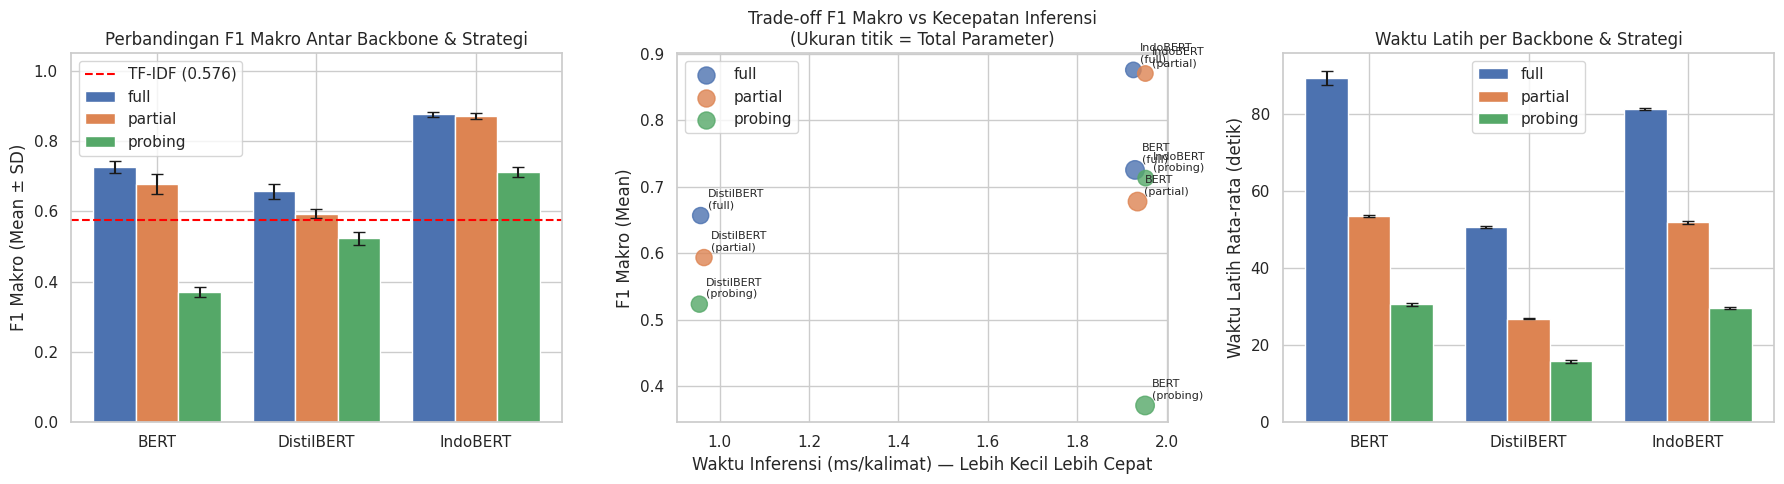

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================================
# VISUALISASI GRAFIK ANALISIS (Q1, Q2, Q3)
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Perbandingan F1 Makro (mean ± SD) vs Baseline TF-IDF
backbones_order = list(BACKBONES_AKTIF.keys())
strategi_order = STRATEGI_AKTIF
x = np.arange(len(backbones_order))
width = 0.8 / len(strategi_order)

for i, strat in enumerate(strategi_order):
    sub = agg[agg["strategi"] == strat].set_index("backbone").reindex(backbones_order)
    axes[0].bar(
        x + (i - (len(strategi_order) - 1) / 2) * width,
        sub["f1_makro_mean"],
        width=width,
        yerr=sub["f1_makro_std"],
        capsize=4,
        label=strat
    )
axes[0].axhline(f1_tfidf, color="red", linestyle="--", linewidth=1.5, label=f"TF-IDF ({f1_tfidf:.3f})")
axes[0].set_xticks(x)
axes[0].set_xticklabels(backbones_order)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("F1 Makro (Mean ± SD)")
axes[0].set_title("Perbandingan F1 Makro Antar Backbone & Strategi")
axes[0].legend()

# 2. Trade-off Akurasi (F1 Makro) vs Kecepatan Inferensi (ms/kalimat)
for strat in strategi_order:
    sub = agg[agg["strategi"] == strat]
    axes[1].scatter(
        sub["inferensi_ms_mean"],
        sub["f1_makro_mean"],
        s=sub["parameter_total"] / 1e6,
        alpha=0.8,
        label=strat
    )
    for _, row in sub.iterrows():
        axes[1].annotate(
            f"{row['backbone']}\n({row['strategi']})",
            (row["inferensi_ms_mean"], row["f1_makro_mean"]),
            textcoords="offset points", xytext=(5, 5), fontsize=8
        )
axes[1].set_xlabel("Waktu Inferensi (ms/kalimat) — Lebih Kecil Lebih Cepat")
axes[1].set_ylabel("F1 Makro (Mean)")
axes[1].set_title("Trade-off F1 Makro vs Kecepatan Inferensi\n(Ukuran titik = Total Parameter)")
axes[1].legend()

# 3. Efisiensi Waktu Latih per Kombinasi
for i, strat in enumerate(strategi_order):
    sub = agg[agg["strategi"] == strat].set_index("backbone").reindex(backbones_order)
    axes[2].bar(
        x + (i - (len(strategi_order) - 1) / 2) * width,
        sub["waktu_latih_mean"],
        width=width,
        yerr=sub["waktu_latih_std"],
        capsize=4,
        label=strat
    )
axes[2].set_xticks(x)
axes[2].set_xticklabels(backbones_order)
axes[2].set_ylabel("Waktu Latih Rata-rata (detik)")
axes[2].set_title("Waktu Latih per Backbone & Strategi")
axes[2].legend()

plt.tight_layout()
plt.savefig(f"grafik_ringkasan_{DATASET_NAME}_{KODE_KONFIG}.png", dpi=150)
plt.show()

# Unduh otomatis kedua file CSV bila dijalankan di Google Colab
try:
    from google.colab import files
    files.download(FILE_HASIL)
    files.download(FILE_REKAP)
except ImportError:
    print(f"Bukan Google Colab. Ambil file langsung di direktori kerja: {FILE_HASIL} dan {FILE_REKAP}")

# Analisis & Jawaban Pertanyaan Riset

## Q1. Backbone dengan trade-off akurasi vs efisiensi terbaik
IndoBERT (full FT) memberi trade-off terbaik: F1 makro 0,8759 ± 0,0078,
waktu latih 81,3 s, inferensi 1,926 ms/kalimat, 124,4 M parameter.
IndoBERT lebih baik dari mBERT (F1 0,7254 ± 0,0172; 89,4 s; 1,929 ms;
177,9 M parameter) di semua sisi. DistilBERT paling cepat (0,958 ms;
50,7 s) tetapi F1 hanya 0,6567 ± 0,0213, dan parameternya 135,3 M
(lebih banyak dari IndoBERT karena vocab multibahasa besar).

## Q2. Apakah strategi hemat komputasi cukup kompetitif?
- IndoBERT: partial turun 0,0054 dari full, lebih kecil dari SD (~0,008)
  sehingga belum dapat dikatakan berbeda. Probing turun 0,163 (bermakna).
- mBERT: partial turun 0,048, probing turun 0,355 (F1 ~0,37, mendekati acak).
- DistilBERT: partial turun 0,063, probing turun 0,133.
- Kesimpulan: partial kompetitif hanya pada IndoBERT; probing tidak
  kompetitif pada semua backbone. Catatan: hanya 3 seed, jadi SD
  hanya indikasi kasar.

## Q3. Rekomendasi
IndoBERT + partial freezing.
Kriteria: F1 makro berada dalam rentang SD dari skor tertinggi, lalu
pilih biaya latih dan memori terendah.
- F1 makro 0,8705 ± 0,0079 (setara full fine-tuning)
- Waktu latih 51,9 s vs 81,3 s (sekitar 36% lebih cepat)
- Memori puncak ~1,7 GB vs ~3,3 GB (sekitar 46% lebih hemat)
- Inferensi ~1,95 ms/kalimat (sama dengan full; freezing tidak
  mempercepat forward pass)
Bila latensi < 1 ms wajib, DistilBERT dapat dipertimbangkan dengan
konsekuensi F1 turun sekitar 0,22.

## Catatan & Keterbatasan
- Subset latih 3.500, 3 seed, satu dataset.
- Sebaran kelas data uji berbeda dari data latih (netral ±18% vs ±10%).
- Waktu inferensi diukur dengan batch 32 pada GPU T4 dalam satu sesi,
  lebih mendekati throughput daripada latensi satu permintaan.
- Baseline TF-IDF di Sel 6 dilatih pada subset (F1 0,5759); pembanding
  di lembar soal (≈ 0,73) memakai data latih penuh.
- mBERT probing (F1 ~0,37) kemungkinan dipengaruhi LR 2e-3, backbone
  beku, dan hanya 3 epoch; ini dugaan yang belum diuji.